<a href="https://colab.research.google.com/github/mrcastilla8/Labs-Mineria/blob/master/Semana%2013/Laboratorio_Santander_Clasificacion_Trabajo_Grupal_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Modelos de Clasificación — Ejercicio 1
## Santander Customer Satisfaction

**Comparación de métodos de escalamiento, clasificadores supervisados y ensambles con validación cruzada y evaluación final.**

## Alcance del estudio

Se presenta el contexto de clasificación del ejercicio, el código inicial de referencia y una implementación reproducible de cuatro métodos de escalamiento, once clasificadores y cinco ensambles. Se utiliza el conjunto de datos completo disponible en `train.csv`, con división estratificada de desarrollo y evaluación final independiente. El procedimiento preserva métricas, gráficos y archivos para análisis posterior.

# Parte A — Exploración y métodos de referencia

Se conserva la estructura original del ejercicio y su código como material de referencia histórica. La evaluación de este estudio utiliza la implementación independiente de la Parte B, con validación estratificada y prevención de fugas de datos.

## Importar librerias

Desde equipos de soporte de primera línea hasta C-suites, la satisfacción del cliente es una medida clave del éxito. Los clientes insatisfechos no se quedan. Además, los clientes descontentos rara vez expresan su insatisfacción antes de irse.

El objetivo es identificar a los clientes insatisfechos en una etapa temprana de su relación. Hacerlo le permitiría a Santander tomar medidas proactivas para mejorar la felicidad de un cliente antes de que sea demasiado tarde.

En esta competencia, trabajará con cientos de funciones anónimas para predecir si un cliente está satisfecho o insatisfecho con su experiencia bancaria.

Se le proporciona un conjunto de datos anonimizados que contiene una gran cantidad de variables numéricas. La columna "OBJETIVO" es la variable a predecir. Es igual a uno para clientes insatisfechos y 0 para clientes satisfechos.

La tarea es predecir la probabilidad de que cada cliente en el conjunto de prueba sea un cliente insatisfecho.
Descripciones de archivos

1. train.csv: el conjunto de entrenamiento que incluye el objetivo  --- 76020
2. test.csv: el conjunto de prueba sin el objetivo  --- 75818
3. sample_submission.csv: un archivo de envío de muestra en el formato correcto

```python
#generales
import numpy as np
import pandas as pd

#gráficas
import seaborn as sns
import matplotlib.pyplot as plt

#procesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split, RandomizedSearchCV

#modelo
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.naive_bayes import GaussianNB

#evaluación
from scipy import stats
from sklearn.metrics import accuracy_score, roc_curve, auc, mean_squared_error, f1_score

import warnings
warnings.filterwarnings('ignore')
```

* Si no cuenta con alguna de las librerias ejecute el seguiente codigo según corresponda

**Instalación mencionada en la plantilla original (referencia, no ejecutar literalmente):**

```bash
pip install catboost
pip install xgboost
pip install lightgbm
pip install seaborn
pip install scipy
```

## Carga de datos

```python
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")
```

## 1. Análisis Exploratorio

**1.1. muestreo aleatorio del conjunto de datos**

```python
train.sample(5)
```

```python
test.sample(5)
```

```python
sample.sample(5)
```

**1.2. Dimención de la estructura**

```python
#determinar la dimensionalidad de los conjuntos de datos
# shape (instancias, concepto)
print("Shape de train dataframe : {}".format(train.shape))
print("Shape de test dataframe : {}".format(test.shape))
print("Shape de sample dataframe : {}".format(sample.shape))
```

**1.3. Descripción y estadística basica**

```python
#Comprobar la existencia de null's en los conjuntos de datos
print('Null en train : {}'.format(train.isnull().sum().any()))
print('Null en test : {}'.format(test.isnull().sum().any()))
```

```python
#análisis estadistico básico de las columnas numericas
train.describe()
```

```python
#tipos de datos
train.info()
```

```python
#tipos de datos
test.info()
```

```python
# Determinar la existencia de duplicados
dupli = train[train.duplicated()]
dupli
```

**1.4. Análisis Gráfico**

```python
plt.figure(figsize = (20,20))
for i in range (50):
    plt.subplot(5, 10, i+1)
    sns.boxplot(train.iloc[:,i])
    plt.xlabel(train.columns[i], size = 10)
```

### 2. Modificación

```python
# remover columnas con valores unicos
for i in train.columns:
    if train[i].nunique() == 1:
        print(i)
        train.drop(i, inplace = True, axis = 1)
        test.drop(i, inplace = True, axis = 1)
```

```python
def Outliers(data, ft):
    IQ1 = data[ft].quantile(0.25)
    IQ3 = data[ft].quantile(0.75)
    IQR = IQ3 - IQ1
    
    lower_bound = IQ1 - 1.5 * IQR
    upper_bound = IQ3 + 1.5 * IQR
    
    return lower_bound, upper_bound
```

```python
def replace_outliers_with_iqr(train):
    # Recorremos cada columna del DataFrame
    
    for i in train.columns:
        if i != 'TARGET':
            # Solo aplicar a columnas numéricas
            if train[i].dtype in ['int64', 'float64']:
                # Obtener los límites de los outliers
                lower_bound, upper_bound = Outliers(train, i)
                
                # Reemplazar valores que están por debajo del límite inferior
                train.loc[train[i] < lower_bound, i] = lower_bound
                
                # Reemplazar valores que están por encima del límite superior
                train.loc[train[i] > upper_bound, i] = upper_bound
            
    return train
```

```python
train = replace_outliers_with_iqr(train)
train
```

```python
print(train['TARGET'].value_counts())
plt.figure(figsize = (8,5))
sns.countplot(x = train['TARGET'])
plt.xlabel('Target', size = 12)
plt.ylabel('Count', size = 12)
plt.title('Distribución en la columna de target antes del remuestreo', size = 12)
```

```python
#eliminación de columnas
test_id = test['ID']
train.drop('ID', inplace = True, axis = 1)
test.drop('ID', inplace = True, axis = 1)
```

**Separación de variables entrada y target**

```python
x = train.drop('TARGET', axis = 1)
x.head()
```

```python
y = train.loc[:, 'TARGET']
y.head()
```

**Técnicas de muestreo**

```python
# Muestreo de los datos, para equilibrar las clases en el target.
sampler = RandomUnderSampler(random_state=123, sampling_strategy=.5)
x, y = sampler.fit_resample(x, y)
```

```python
print(y.value_counts())
plt.figure(figsize = (8,5))
sns.countplot(x = y)
plt.xlabel('Target', size = 12)
plt.ylabel('Count', size = 12)
plt.title('Distribución en la columna de target despues del remuestreo', size = 12)
```

```python
# aplicar técnicas de escalado
# máximos minimos y standar

col = x.columns
std = StandardScaler()
x_std = std.fit_transform(x)
x_std = pd.DataFrame(data = x_std, columns = col)

mms = MinMaxScaler()
x_mms = mms.fit_transform(x)
x_mms = pd.DataFrame(data = x_mms, columns = col)
```

### 3. test y entrenamiento

```python
x_mms.head()
```

**Creación de clase model**

```python
def Models(model, name, d, xtrain, ytrain, xtest, ytest):
    print("Working on {} model".format(name))
    
    cla = model
    cla.fit(xtrain, ytrain)
    
    predicted = cla.predict(xtrain)
    tr_auc = accuracy_score(predicted, ytrain)*100
    
    predicted = cla.predict(xtest)
    te_auc = accuracy_score(predicted, ytest)*100
    
    F1 = f1_score(predicted, ytest)
    fpr, tpr, threshould = roc_curve(predicted, ytest)
    AUC = auc(fpr, tpr)
    
    d['Name'].append(name)
    d['Training ACU'].append(tr_auc)
    d['Testing ACU'].append(te_auc)
    d['F1'].append(F1)
    d['AUC'].append(AUC)
    
    print("**********"*5)
    print()
    return d, cla
```

**Evaluación de modelos segú el conjunto**

```python
l = [[x, 'Normal'], [x_std, 'Standard'], [x_mms, 'Min Max']]
final = []
model_fit = []
for i in l:
    xtrain, xtest, ytrain, ytest = train_test_split(i[0], y, test_size = 0.25, random_state = 42, stratify = y)
    
    d = {'Name' : [], 'Training ACU': [], 'Testing ACU': [], 'F1': [], 'AUC': []}
    
    models = [
        [RandomForestClassifier(n_estimators = 200), 'Random Forest'],
        [DecisionTreeClassifier(), 'Decision Tree'],
        [XGBClassifier(tree_method='gpu_hist'), 'XGBoost'],
        [CatBoostClassifier(task_type="GPU"), 'CatBoost'],
        [GaussianNB(), 'Naive Bayes'],
        [LogisticRegression(), 'Logistic Regression']
    ]

    for model in models:
        d, m = Models(model[0], model[1], d, xtrain, ytrain, xtest, ytest)
        model_fit.append([m, model[1], i[1]])
    final.append(d)
```

**Evaluación de los resultados por modelo y tipo de conjunto de datos**

```python
name = ['Normal', 'Standard', 'Min Max']
for i in range (len(name)):
    print(name[i])
    acu_data = pd.DataFrame(data = final[i])
    print(acu_data)
    print("******"*12)
```

# Ejercicio de clasificación supervisada

El ejercicio considera cuatro transformaciones de escala, cinco clasificadores adicionales y cinco modelos híbridos. Sus componentes se desarrollan y comparan en la Parte B, bajo un protocolo uniforme de validación.

# Parte B — Desarrollo experimental y evaluación reproducible

Los experimentos se ajustan exclusivamente con datos de desarrollo. La comparación incluye 44 configuraciones individuales (11 clasificadores × 4 escaladores) y cinco modelos híbridos. El modelo y la configuración de cada familia se seleccionan por validación cruzada antes de evaluar el conjunto reservado.

**Protocolo:** semilla fija 42; división estratificada 75 % / 25 %; dos folds externos y tres folds internos para Stacking; selección por ROC-AUC, Recall y F1; métricas del holdout reportadas sin utilizarlas para seleccionar configuraciones. El registro de tiempos distingue ajuste y predicción. Los resultados de cada fold se conservan por separado para favorecer su reproducibilidad.

## 4.1. Preparación e interfaz compartida

La preparación de datos y las funciones de evaluación establecen un procedimiento común para todas las familias de clasificadores. Las transformaciones se ajustan utilizando únicamente la partición de entrenamiento que corresponda.

### 4.1.1. Entorno de ejecución y fuentes de datos

Se utilizan Python, scikit-learn, XGBoost, LightGBM y CatBoost. Los archivos se localizan en el entorno de Colab o Google Drive. Las huellas SHA-256 de los datos y el protocolo permiten identificar de forma inequívoca cada experimento y sus resultados.

In [1]:
from pathlib import Path
import os, sys, time, json, hashlib, subprocess, importlib.util, warnings
from datetime import datetime, timezone
from importlib.metadata import version as package_version, PackageNotFoundError
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from packaging.version import Version

SEMILLA = 42
FOLDS_EXTERNOS = 2
FOLDS_STACKING = 3
VARIABLES_KNN = 12
VERSION_ANALISIS = 'santander-final-estructura-v2'
N_HILOS = max(1, min(2, os.cpu_count() or 2))
np.random.seed(SEMILLA)

for modulo, paquete in [('xgboost','xgboost'), ('lightgbm','lightgbm'), ('catboost','catboost')]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])
if Version(sklearn.__version__) >= Version('1.8'):
    try:
        version_catboost = Version(package_version('catboost'))
    except PackageNotFoundError:
        version_catboost = Version('0')
    if version_catboost < Version('1.2.9'):
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', 'catboost>=1.2.9'])

from threadpoolctl import threadpool_limits
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve)
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, VotingClassifier, StackingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

sns.set_theme(style='whitegrid')
EN_COLAB = importlib.util.find_spec('google.colab') is not None
if EN_COLAB and not Path('/content/drive/MyDrive').exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception as exc:
        print('Google Drive no montado:', type(exc).__name__)

rutas = []
if os.environ.get('SANTANDER_DATA_DIR'):
    rutas.append(Path(os.environ['SANTANDER_DATA_DIR']))
rutas += [Path('/content'), Path('/content/drive/MyDrive/Santander'),
          Path('/content/drive/MyDrive/SantanderCustomerSatisfaction'),
          Path('/content/drive/MyDrive'), Path.cwd()]
DATA_DIR = next((p for p in rutas if (p/'train.csv').is_file()), None)
if DATA_DIR is None:
    if not EN_COLAB:
        raise FileNotFoundError('Se necesita train.csv de Santander Customer Satisfaction.')
    from google.colab import files
    print('Selecciona train.csv de Santander Customer Satisfaction.')
    files.upload()
    DATA_DIR = Path('/content')
if not (DATA_DIR/'train.csv').is_file():
    raise FileNotFoundError(f'No se encontró train.csv en {DATA_DIR}')

raiz_salida = (Path('/content/drive/MyDrive/Santander/Resultados_Final')
               if Path('/content/drive/MyDrive').exists()
               else Path('/content/Santander_Resultados_Final'))

def sha256_archivo(ruta):
    digest = hashlib.sha256()
    with open(ruta, 'rb') as fh:
        for bloque in iter(lambda: fh.read(8*1024*1024), b''):
            digest.update(bloque)
    return digest.hexdigest()

FIRMA_DATOS = sha256_archivo(DATA_DIR/'train.csv')
FIRMA_PROTOCOLO = hashlib.sha256(json.dumps({
    'version': VERSION_ANALISIS, 'datos': FIRMA_DATOS,
    'seed': SEMILLA, 'externos': FOLDS_EXTERNOS,
    'internos': FOLDS_STACKING, 'knn_features': VARIABLES_KNN,
    'sklearn': sklearn.__version__
}, sort_keys=True).encode()).hexdigest()[:16]
SALIDA = raiz_salida / FIRMA_PROTOCOLO
(SALIDA/'cv').mkdir(parents=True, exist_ok=True)
(SALIDA/'holdout').mkdir(parents=True, exist_ok=True)
print('Entorno:', 'Colab' if EN_COLAB else 'Python', '| scikit-learn:', sklearn.__version__)
print('Datos:', DATA_DIR/'train.csv', '| huella:', FIRMA_DATOS[:12])
print('Resultados:', SALIDA)
print('Filas: dataset completo | hilos por estimador:', N_HILOS)


Mounted at /content/drive
Entorno: Colab | scikit-learn: 1.6.1
Datos: /content/train.csv | huella: 3a3214dbcca2
Resultados: /content/drive/MyDrive/Santander/Resultados_Final/dd7e6679a71c26b2
Filas: dataset completo | hilos por estimador: 2


### 4.1.2. Carga de datos y división estratificada

Se lee `train.csv`, se retira `ID` de las características y se conserva `TARGET` como variable binaria. La muestra se divide en 75 % de desarrollo y 25 % de holdout con estratificación por clase y semilla 42; no se remuestrea ningún conjunto.

In [2]:
datos = pd.read_csv(DATA_DIR/'train.csv', low_memory=False)
if not {'ID','TARGET'} <= set(datos.columns):
    raise ValueError('train.csv debe contener las columnas ID y TARGET.')
if datos['ID'].isna().any() or datos['ID'].duplicated().any():
    raise ValueError('La columna ID debe contener identificadores únicos, sin nulos.')
if datos['TARGET'].isna().any() or set(datos['TARGET'].unique()) != {0,1}:
    raise ValueError('TARGET debe contener las dos clases 0 y 1, sin nulos.')
X = datos.drop(columns=['ID','TARGET'])
if not X.select_dtypes(exclude='number').empty:
    raise ValueError('Se requieren características numéricas en el conjunto Santander.')
X = X.astype('float32')
y = datos['TARGET'].astype('int8')
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=.25, stratify=y, random_state=SEMILLA)
assert X_train.index.intersection(X_holdout.index).empty
assert X_train.columns.equals(X_holdout.columns)
assert len(X_train)+len(X_holdout)==len(datos)
assert min(y_train.value_counts()) >= FOLDS_EXTERNOS * FOLDS_STACKING
resumen_datos = pd.DataFrame({
    'conjunto':['Total','Desarrollo (75 %)','Holdout (25 %)'],
    'registros':[len(y),len(y_train),len(y_holdout)],
    'tasa_insatisfaccion':[y.mean(), y_train.mean(), y_holdout.mean()]})
display(resumen_datos)
print('Características:', X.shape[1], '| datos faltantes:', int(X.isna().sum().sum()))


,conjunto,registros,tasa_insatisfaccion
0,Total,76020,0.039569
1,Desarrollo (75 %),57015,0.039569
2,Holdout (25 %),19005,0.039569


Características: 369 | datos faltantes: 0


### Interpretación del conjunto y del holdout

El conjunto analizado contiene 76 020 observaciones y 369 características predictoras. La clase `TARGET = 1`, asociada con insatisfacción, representa aproximadamente el 3,9569 % de los registros; por tanto, alrededor del 96,0431 % corresponde a `TARGET = 0`. Esta distribución evidencia un desbalanceo marcado: una regla que clasifique siempre como satisfecho alcanzaría cerca de 96,04 % de Accuracy, aunque no identificaría a ningún cliente insatisfecho.

La partición estratificada asignó 57 015 registros al desarrollo y 19 005 al holdout, manteniendo la proporción de clases en ambos subconjuntos. La estratificación hace más comparable la composición de las particiones y reduce el riesgo de que la escasa clase positiva quede subrepresentada en una de ellas. Mantener el holdout al margen del ajuste y de la selección permite usarlo como evaluación final de las configuraciones escogidas mediante validación cruzada.

En este contexto, Accuracy por sí sola es insuficiente. Precision expresa qué proporción de las alertas positivas corresponde realmente a insatisfechos; Recall cuantifica cuántos insatisfechos se recuperan; y F1 resume el equilibrio entre ambas. ROC-AUC mide la capacidad de ordenar positivos por encima de negativos a través de umbrales, mientras que Average Precision resume el comportamiento de precisión y recall en la clase positiva, cuya prevalencia es baja. Estas medidas responden preguntas distintas y deben interpretarse conjuntamente con la matriz de confusión y la regla de decisión aplicada.

### 4.1.3. Preprocesamiento reproducible y control de fuga de datos

La imputación por mediana y la eliminación de características vacías o constantes se ajustan únicamente en cada partición de entrenamiento. El KNN utiliza selección supervisada de 12 características dentro de cada fold; las ramas del Stacking contienen su propio preprocesamiento para aislar correctamente la validación interna.

In [3]:
class EliminarColumnasVacias(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        matriz = np.asarray(X, dtype=np.float32)
        self.n_features_in_ = matriz.shape[1]
        self.mascara_ = ~np.isnan(matriz).all(axis=0)
        if not np.any(self.mascara_):
            raise ValueError('Todas las características están vacías en este fold.')
        return self
    def transform(self, X):
        matriz = np.asarray(X, dtype=np.float32)
        if matriz.shape[1] != self.n_features_in_:
            raise ValueError('Número de características diferente al entrenamiento.')
        return matriz[:,self.mascara_]

def preprocesador_base():
    return Pipeline([
        ('vacías', EliminarColumnasVacias()),
        ('imputacion', SimpleImputer(strategy='median')),
        ('varianza', VarianceThreshold(threshold=0.0)),
    ])

def pipeline_individual(estimador, nombre, escalador=None):
    pasos = list(preprocesador_base().steps)
    if escalador is not None:
        pasos.append(('escalado', clone(escalador)))
    if nombre=='knn':
        pasos.append(('seleccion', SelectKBest(f_classif, k=VARIABLES_KNN)))
    pasos.append(('clasificador', clone(estimador)))
    return Pipeline(pasos)

def pipeline_stacking_base(estimador, nombre, necesita_escala=False):
    return pipeline_individual(estimador, nombre,
        escalador=StandardScaler() if necesita_escala else None)


### 4.1.4. Funciones y métricas de evaluación

Las funciones de evaluación centralizan el cálculo de Accuracy, Precision, Recall, F1, ROC-AUC, Average Precision y los tiempos de ajuste y predicción. Las puntuaciones continuas sustentan ROC-AUC y Average Precision; el modelo de votación dura no genera esas puntuaciones y mantiene sus valores ausentes.

In [4]:
def guardar_json(ruta, datos):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_suffix(ruta.suffix+'.tmp')
    with open(temporal,'w',encoding='utf-8') as f:
        json.dump(datos, f, ensure_ascii=False, indent=2, allow_nan=False)
    os.replace(temporal,ruta)

def cargar_json(ruta):
    with open(ruta,encoding='utf-8') as f:
        return json.load(f)

def matriz_32(x):
    return np.asarray(x,dtype=np.float32,order='C')

def preparar_fold(fi, vi, indice):
    X_f, X_v = X_train.iloc[fi], X_train.iloc[vi]
    y_f, y_v = y_train.iloc[fi], y_train.iloc[vi]
    base = preprocesador_base()
    bt = matriz_32(base.fit_transform(X_f))
    bv = matriz_32(base.transform(X_v))
    escalados = {}
    for nombre, original in escaladores.items():
        scaler = clone(original)
        t = matriz_32(scaler.fit_transform(bt))
        v = matriz_32(scaler.transform(bv))
        escalados[nombre] = (t,v)
    print(f'Fold {indice}/{FOLDS_EXTERNOS}: preprocesamiento compartido listo ({bt.shape[1]} variables).')
    return {'fit':X_f,'eval':X_v,'y_fit':y_f,'y_eval':y_v,
            'base':(bt,bv),'escalados':escalados}

def preparar_holdout():
    base=preprocesador_base()
    bt=matriz_32(base.fit_transform(X_train))
    bv=matriz_32(base.transform(X_holdout))
    escalados={}
    for nombre, original in escaladores.items():
        scaler=clone(original)
        escalados[nombre]=(matriz_32(scaler.fit_transform(bt)),
                            matriz_32(scaler.transform(bv)))
    return {'fit':X_train,'eval':X_holdout,'y_fit':y_train,'y_eval':y_holdout,
            'base':(bt,bv),'escalados':escalados}

def especificaciones():
    configs=[]
    for tipo, grupo in [('original', modelos_originales),('nuevo', modelos_nuevos)]:
        for nombre in grupo:
            for escalador in escaladores:
                configs.append((tipo,nombre,escalador))
    for nombre in modelos_hibridos:
        configs.append(('hibrido',nombre,'sin_escalado'))
    assert len(configs)==49
    return configs

def puntaje_clase_1(modelo,Xv):
    clases=list(modelo.classes_)
    if 1 not in clases:
        raise ValueError('No se encontró la clase positiva TARGET=1.')
    if hasattr(modelo,'predict_proba'):
        p=np.asarray(modelo.predict_proba(Xv))
        return p[:,clases.index(1)]
    if hasattr(modelo,'decision_function'):
        scores=np.asarray(modelo.decision_function(Xv))
        if scores.ndim==1:
            return scores if clases[-1]==1 else -scores
        return scores[:,clases.index(1)]
    return None

def preparar_estimador(tipo,nombre,escalador,matrices):
    if tipo=='hibrido':
        modelo=clone(modelos_hibridos[nombre])
        if nombre.startswith(('H4_','H5_')):
            return modelo, matrices['fit'], matrices['eval']
        return modelo, *matrices['base']
    modelo=clone((modelos_originales if tipo=='original' else modelos_nuevos)[nombre])
    if nombre=='knn':
        modelo=Pipeline([('seleccion', SelectKBest(f_classif,k=VARIABLES_KNN)),
                         ('clasificador',modelo)])
    return modelo, *matrices['escalados'][escalador]

def medir_configuracion(tipo,nombre,escalador,matrices,guardar_prediccion=False):
    modelo,X_f,X_v=preparar_estimador(tipo,nombre,escalador,matrices)
    y_f,y_v=matrices['y_fit'],matrices['y_eval']
    with threadpool_limits(limits=N_HILOS):
        inicio=time.perf_counter()
        modelo.fit(X_f,y_f)
        t_ajuste=time.perf_counter()-inicio
        inicio=time.perf_counter()
        pred=modelo.predict(X_v)
        score=puntaje_clase_1(modelo,X_v)
        t_pred=time.perf_counter()-inicio
    y_real=np.asarray(y_v)
    registro={
        'tipo':tipo,'modelo':nombre,'escalador':escalador,
        'accuracy':float(accuracy_score(y_real,pred)),
        'precision':float(precision_score(y_real,pred,zero_division=0)),
        'recall':float(recall_score(y_real,pred,zero_division=0)),
        'f1':float(f1_score(y_real,pred,zero_division=0)),
        'roc_auc':float(roc_auc_score(y_real,score)) if score is not None and len(np.unique(y_real))==2 else None,
        'average_precision':float(average_precision_score(y_real,score)) if score is not None else None,
        'tiempo_ajuste_s':round(t_ajuste,4),
        'tiempo_prediccion_s':round(t_pred,4),
    }
    if guardar_prediccion:
        return registro, {'y_real':y_real,'y_pred':np.asarray(pred),
                          'score':np.asarray(score) if score is not None else None}
    return registro


## 4.2. Cuatro métodos de escalamiento

Los cuatro escaladores se mantienen como transformadores no ajustados hasta su uso en los conjuntos de desarrollo correspondientes. Las matrices transformadas se preparan una vez por fold externo y se reutilizan en las configuraciones individuales de ese fold.

### 4.2.1. StandardScaler

El escalamiento estándar centra los valores mediante su media y los normaliza según su desviación estándar, calculadas con los datos de entrenamiento.

In [5]:
escaladores = {'standard': StandardScaler()}
print('StandardScaler: transformación basada en media y desviación estándar.')


StandardScaler: transformación basada en media y desviación estándar.


### 4.2.2. MinMaxScaler

El escalamiento Min-Max transforma las características hacia el intervalo [0, 1] según los extremos observados en entrenamiento; el intervalo no se reestima sobre validación ni holdout.

In [6]:
escaladores['minmax'] = MinMaxScaler()
print('MinMaxScaler: intervalo [0, 1] aprendido exclusivamente en entrenamiento.')


MinMaxScaler: intervalo [0, 1] aprendido exclusivamente en entrenamiento.


### 4.2.3. RobustScaler

RobustScaler utiliza la mediana y el rango intercuartílico, lo que limita la influencia de observaciones extremas en los parámetros de transformación.

In [7]:
escaladores['robust'] = RobustScaler()
print('RobustScaler: transformación basada en mediana y rango intercuartílico.')


RobustScaler: transformación basada en mediana y rango intercuartílico.


### 4.2.4. QuantileTransformer

QuantileTransformer representa las distribuciones marginales mediante cuantiles y una transformación hacia la distribución normal. Se utilizan hasta 256 cuantiles con muestreo de referencia controlado y semilla fija.

In [8]:
escaladores['quantile'] = QuantileTransformer(
    n_quantiles=256, output_distribution='normal', subsample=10000, random_state=SEMILLA
)
assert set(escaladores) == {'standard', 'minmax', 'robust', 'quantile'}
print('Transformaciones:', ', '.join(escaladores))


Transformaciones: standard, minmax, robust, quantile


## 4.3. Seis clasificadores originales como línea base

### 4.3.1. Clasificadores de referencia

Los seis clasificadores de referencia incluyen Random Forest, Decision Tree, XGBoost, CatBoost, Gaussian Naive Bayes y Logistic Regression. Se utilizan parámetros computacionalmente acotados y CPU para hacer reproducible el procedimiento completo sin excluir observaciones.

In [9]:
modelos_originales = {
    'random_forest': RandomForestClassifier(n_estimators=90, min_samples_leaf=2,
        class_weight='balanced', n_jobs=N_HILOS, random_state=SEMILLA),
    'decision_tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10,
        class_weight='balanced', random_state=SEMILLA),
    'xgboost': XGBClassifier(n_estimators=90, max_depth=5, learning_rate=.06,
        subsample=.8, colsample_bytree=.8, objective='binary:logistic',
        eval_metric='logloss', tree_method='hist', n_jobs=N_HILOS,
        random_state=SEMILLA),
    'catboost': CatBoostClassifier(iterations=90, depth=6, learning_rate=.06,
        loss_function='Logloss', verbose=False, allow_writing_files=False,
        thread_count=N_HILOS, random_seed=SEMILLA),
    'gaussian_nb': GaussianNB(),
    'logistic_regression': LogisticRegression(C=1.0, max_iter=1500,
        solver='liblinear', class_weight='balanced', random_state=SEMILLA),
}
assert len(modelos_originales)==6
print('Clasificadores de referencia:', ', '.join(modelos_originales))


Clasificadores de referencia: random_forest, decision_tree, xgboost, catboost, gaussian_nb, logistic_regression


## 4.4. Cinco clasificadores adicionales

Se consideran Linear SVC, AdaBoost, KNN, LightGBM y Extra Trees como modelos adicionales. Para todos se preserva la misma partición y se emplean los mismos folds de validación externa.

### 4.4.1. SVM de clasificación (LinearSVC)

Linear SVC estima una frontera lineal de clasificación y permite obtener puntuaciones de decisión continuas para ROC-AUC sin requerir calibración probabilística.

In [10]:
modelos_nuevos = {'svm_lineal': LinearSVC(C=1, dual=False, tol=1e-3, max_iter=4000,
                            random_state=SEMILLA)}
print('LinearSVC incorporado al conjunto de clasificadores.')


LinearSVC incorporado al conjunto de clasificadores.


### 4.4.2. AdaBoostClassifier

AdaBoost combina árboles débiles ajustados de forma secuencial para corregir los errores acumulados. Se conserva la semilla y se fija el presupuesto de estimadores.

In [11]:
modelos_nuevos['adaboost'] = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
        random_state=SEMILLA), n_estimators=60, learning_rate=.5, random_state=SEMILLA)
print('AdaBoost incorporado al conjunto de clasificadores.')


AdaBoost incorporado al conjunto de clasificadores.


### 4.4.3. KNeighborsClassifier (KNN)

KNN realiza clasificación por proximidad con 11 vecinos y ponderación por distancia. Para reducir el costo sobre datos de alta dimensión, se seleccionan 12 variables mediante ANOVA sobre cada entrenamiento y se utiliza un índice BallTree sin aproximar las distancias.

In [12]:
modelos_nuevos['knn'] = KNeighborsClassifier(n_neighbors=11, weights='distance',
        algorithm='ball_tree', leaf_size=60, n_jobs=N_HILOS)
print(f'KNN: 11 vecinos, selección supervisada de {VARIABLES_KNN} características dentro de cada fold.')


KNN: 11 vecinos, selección supervisada de 12 características dentro de cada fold.


### 4.4.4. LightGBMClassifier

LightGBM emplea crecimiento de árboles y aprendizaje por gradiente, con un presupuesto de entrenamiento adecuado para CPU y semilla reproducible.

In [13]:
modelos_nuevos['lightgbm'] = LGBMClassifier(objective='binary', n_estimators=90, learning_rate=.06,
        num_leaves=31, min_child_samples=20, colsample_bytree=.8,
        device_type='cpu', n_jobs=N_HILOS, random_state=SEMILLA, verbosity=-1)
print('LightGBM incorporado al conjunto de clasificadores.')


LightGBM incorporado al conjunto de clasificadores.


### 4.4.5. ExtraTreesClassifier

Extra Trees incorpora aleatoriedad en los umbrales de división de los árboles. Su comportamiento se contrasta con Random Forest dentro del mismo esquema de validación.

In [14]:
modelos_nuevos['extra_trees'] = ExtraTreesClassifier(n_estimators=90, min_samples_leaf=2,
        max_features='sqrt', n_jobs=N_HILOS, random_state=SEMILLA)
assert len(modelos_nuevos)==5
print('Clasificadores adicionales:', ', '.join(modelos_nuevos))


Clasificadores adicionales: svm_lineal, adaboost, knn, lightgbm, extra_trees


## 4.5. Cinco modelos híbridos (ensambles)

Los cinco modelos híbridos combinan clasificadores previamente definidos. Los ensambles de votación agregan etiquetas o probabilidades; los modelos Stacking aprenden a combinar predicciones de sus componentes mediante validación cruzada interna.

### 4.5.1. H1 — VotingClassifier Hard: Logistic Regression + Decision Tree + KNN

La votación dura integra las etiquetas de Logistic Regression, Decision Tree y KNN por mayoría. No ofrece puntuaciones continuas para la construcción de la curva ROC.

In [15]:
modelos_hibridos = {'H1_voting_hard': VotingClassifier(estimators=[
        ('logistic_regression', Pipeline([('escalado',StandardScaler()),
            ('clasificador',clone(modelos_originales['logistic_regression']))])),
        ('decision_tree', clone(modelos_originales['decision_tree'])),
        ('knn', Pipeline([('escalado',StandardScaler()),
            ('seleccion',SelectKBest(f_classif,k=VARIABLES_KNN)),
            ('clasificador',clone(modelos_nuevos['knn']))])),
    ], voting='hard', n_jobs=1)}
print('H1: votación mayoritaria (Logistic Regression, Decision Tree y KNN).')


H1: votación mayoritaria (Logistic Regression, Decision Tree y KNN).


### 4.5.2. H2 — VotingClassifier Soft: Random Forest + AdaBoost + Logistic Regression

La votación probabilística promedia las probabilidades de Random Forest, AdaBoost y Logistic Regression. Las transformaciones necesarias para el modelo lineal se ajustan dentro de su rama de entrenamiento.

In [16]:
modelos_hibridos['H2_voting_soft'] = VotingClassifier(estimators=[
        ('random_forest',clone(modelos_originales['random_forest'])),
        ('adaboost',clone(modelos_nuevos['adaboost'])),
        ('logistic_regression',Pipeline([('escalado',StandardScaler()),
            ('clasificador',clone(modelos_originales['logistic_regression']))])),
    ], voting='soft', n_jobs=1)
print('H2: votación probabilística (Random Forest, AdaBoost y Logistic Regression).')


H2: votación probabilística (Random Forest, AdaBoost y Logistic Regression).


### 4.5.3. H3 — VotingClassifier Soft: XGBoost + LightGBM + CatBoost

Este ensamble combina las probabilidades de XGBoost, LightGBM y CatBoost, todos configurados para entrenamiento sobre CPU.

In [17]:
modelos_hibridos['H3_voting_soft_boosting'] = VotingClassifier(estimators=[
        ('xgboost',clone(modelos_originales['xgboost'])),
        ('lightgbm',clone(modelos_nuevos['lightgbm'])),
        ('catboost',clone(modelos_originales['catboost'])),
    ], voting='soft', n_jobs=1)
print('H3: votación probabilística (XGBoost, LightGBM y CatBoost).')


H3: votación probabilística (XGBoost, LightGBM y CatBoost).


### 4.5.4. H4 — StackingClassifier: SVM + KNN + Random Forest

Stacking H4 integra SVM lineal, KNN y Random Forest. Sus ramas contienen la imputación, selección y escalamiento correspondientes, aprendidos dentro de la validación interna; una regresión logística conforma el metamodelo.

In [18]:
cv_stacking = StratifiedKFold(n_splits=FOLDS_STACKING, shuffle=True,
                                    random_state=SEMILLA)
modelos_hibridos['H4_stacking_svm'] = StackingClassifier(estimators=[
        ('svm_lineal',pipeline_stacking_base(modelos_nuevos['svm_lineal'],'svm_lineal',True)),
        ('knn',pipeline_stacking_base(modelos_nuevos['knn'],'knn',True)),
        ('random_forest',pipeline_stacking_base(modelos_originales['random_forest'],'random_forest')),
    ], final_estimator=LogisticRegression(max_iter=1500,random_state=SEMILLA),
       cv=cv_stacking, stack_method='auto', n_jobs=1, passthrough=False)
print('H4: stacking de SVM, KNN y Random Forest con CV interna estratificada.')


H4: stacking de SVM, KNN y Random Forest con CV interna estratificada.


### 4.5.5. H5 — StackingClassifier: Decision Tree + Extra Trees + AdaBoost

Stacking H5 integra Decision Tree, Extra Trees y AdaBoost con un metamodelo de regresión logística. Cada estimador base incorpora su propio preprocesamiento para evitar el uso de información entre folds internos.

In [19]:
modelos_hibridos['H5_stacking_arboles'] = StackingClassifier(estimators=[
        ('decision_tree',pipeline_stacking_base(modelos_originales['decision_tree'],'decision_tree')),
        ('extra_trees',pipeline_stacking_base(modelos_nuevos['extra_trees'],'extra_trees')),
        ('adaboost',pipeline_stacking_base(modelos_nuevos['adaboost'],'adaboost')),
    ], final_estimator=LogisticRegression(max_iter=1500,random_state=SEMILLA),
       cv=cv_stacking, stack_method='auto', n_jobs=1, passthrough=False)
assert len(modelos_hibridos)==5
for grupo in (modelos_originales,modelos_nuevos,modelos_hibridos):
    for estimador in grupo.values():
        clone(estimador)
print('Cinco ensambles definidos y clonables.')


Cinco ensambles definidos y clonables.


## 4.6. Validación, evaluación final y resultados

### 4.6.1. Validación cruzada y selección de configuraciones

Las configuraciones individuales se comparan bajo los cuatro escaladores y los híbridos bajo sus transformaciones internas. La selección considera solamente los resultados de validación cruzada, con el holdout reservado para una evaluación final única.

In [20]:
CONFIGURACIONES = especificaciones()
FOLDS = list(StratifiedKFold(n_splits=FOLDS_EXTERNOS,shuffle=True,
                            random_state=SEMILLA).split(X_train,y_train))

DATOS_CV = [preparar_fold(fi,vi,i) for i,(fi,vi) in enumerate(FOLDS,1)]
filas_cv, detalle_cv = [], []
inicio_cv = time.perf_counter()
for numero,(tipo,nombre,esc) in enumerate(CONFIGURACIONES,1):
    filas=[]
    for fold,datos_fold in enumerate(DATOS_CV,1):
        archivo = SALIDA/'cv'/f'{tipo}__{nombre}__{esc}__fold{fold}.json'
        if archivo.is_file():
            fila=cargar_json(archivo)
            print(f'CV {numero:02d}/49 · fold {fold}/{FOLDS_EXTERNOS} · {nombre}/{esc} recuperado')
        else:
            print(f'CV {numero:02d}/49 · fold {fold}/{FOLDS_EXTERNOS} · {nombre}/{esc} iniciando...',flush=True)
            t0=time.perf_counter()
            fila=medir_configuracion(tipo,nombre,esc,datos_fold)
            fila['fold']=fold
            fila['duracion_total_s']=round(time.perf_counter()-t0,4)
            guardar_json(archivo,fila)
            print(f'CV {numero:02d}/49 · fold {fold}/{FOLDS_EXTERNOS} completado en '
                  f'{fila["duracion_total_s"]:.1f} s',flush=True)
        filas.append(fila)
        detalle_cv.append(fila)
    resumen={'tipo':tipo,'modelo':nombre,'escalador':esc,'folds':len(filas),'estado':'OK'}
    for metrica in ['accuracy','precision','recall','f1','roc_auc','average_precision',
                    'tiempo_ajuste_s','tiempo_prediccion_s']:
        valores=pd.to_numeric(pd.Series([fila[metrica] for fila in filas]),errors='coerce')
        resumen['cv_'+metrica]=float(valores.mean()) if valores.notna().any() else np.nan
    filas_cv.append(resumen)
    pd.DataFrame(filas_cv).to_csv(SALIDA/'validacion_parcial.csv',index=False)
    print(f'CV {numero:02d}/49 · {tipo}/{nombre}/{esc} OK',flush=True)

tabla_validacion_ultima = pd.DataFrame(filas_cv)
tabla_detalle_cv = pd.DataFrame(detalle_cv)
assert len(tabla_validacion_ultima)==49 and tabla_validacion_ultima['estado'].eq('OK').all()
assert len(tabla_detalle_cv)==49*FOLDS_EXTERNOS

tabla_validacion_ultima.to_csv(SALIDA/'validacion_cv.csv',index=False)
tabla_detalle_cv.to_csv(SALIDA/'validacion_folds.csv',index=False)
print(f'Validación cruzada completada: {len(tabla_validacion_ultima)} configuraciones '
      f'en {(time.perf_counter()-inicio_cv)/60:.1f} minutos de esta sesión.')

def clave_seleccion(fila):
    auc = fila['cv_roc_auc']
    auc = float(auc) if pd.notna(auc) else -1.0
    return (auc, float(fila['cv_recall']), float(fila['cv_f1']))

seleccionados=[]
for (tipo,nombre),grupo in tabla_validacion_ultima.groupby(['tipo','modelo'],sort=False):

    elegido=max(grupo.to_dict('records'),key=clave_seleccion)
    seleccionados.append(elegido)
tabla_seleccion=pd.DataFrame(seleccionados)
assert len(tabla_seleccion)==16
tabla_seleccion.to_csv(SALIDA/'seleccion_modelos.csv',index=False)
display(tabla_seleccion[['tipo','modelo','escalador','cv_roc_auc','cv_recall','cv_f1',
                        'cv_tiempo_ajuste_s']].sort_values(
    ['cv_roc_auc','cv_recall','cv_f1'],ascending=False,na_position='last').reset_index(drop=True))


Fold 1/2: preprocesamiento compartido listo (295 variables).
Fold 2/2: preprocesamiento compartido listo (304 variables).
CV 01/49 · fold 1/2 · random_forest/standard iniciando...
CV 01/49 · fold 1/2 completado en 12.7 s
CV 01/49 · fold 2/2 · random_forest/standard iniciando...
CV 01/49 · fold 2/2 completado en 13.0 s
CV 01/49 · original/random_forest/standard OK
CV 02/49 · fold 1/2 · random_forest/minmax iniciando...
CV 02/49 · fold 1/2 completado en 7.8 s
CV 02/49 · fold 2/2 · random_forest/minmax iniciando...
CV 02/49 · fold 2/2 completado en 5.6 s
CV 02/49 · original/random_forest/minmax OK
CV 03/49 · fold 1/2 · random_forest/robust iniciando...
CV 03/49 · fold 1/2 completado en 7.8 s
CV 03/49 · fold 2/2 · random_forest/robust iniciando...
CV 03/49 · fold 2/2 completado en 5.5 s
CV 03/49 · original/random_forest/robust OK
CV 04/49 · fold 1/2 · random_forest/quantile iniciando...
CV 04/49 · fold 1/2 completado en 6.2 s
CV 04/49 · fold 2/2 · random_forest/quantile iniciando...
CV 04/

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


CV 37/49 · fold 1/2 completado en 2.1 s
CV 37/49 · fold 2/2 · lightgbm/standard iniciando...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


CV 37/49 · fold 2/2 completado en 2.0 s
CV 37/49 · nuevo/lightgbm/standard OK
CV 38/49 · fold 1/2 · lightgbm/minmax iniciando...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (14 outputs left out)

CV 47/49 · fold 2/2 completado en 12.5 s
CV 47/49 · hibrido/H3_voting_soft_boosting/sin_escalado OK
CV 48/49 · fold 1/2 · H4_stacking_svm/sin_escalado iniciando...


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


CV 48/49 · fold 1/2 completado en 983.8 s
CV 48/49 · fold 2/2 · H4_stacking_svm/sin_escalado iniciando...
CV 48/49 · fold 2/2 completado en 990.9 s
CV 48/49 · hibrido/H4_stacking_svm/sin_escalado OK
CV 49/49 · fold 1/2 · H5_stacking_arboles/sin_escalado iniciando...
CV 49/49 · fold 1/2 completado en 49.3 s
CV 49/49 · fold 2/2 · H5_stacking_arboles/sin_escalado iniciando...
CV 49/49 · fold 2/2 completado en 52.2 s
CV 49/49 · hibrido/H5_stacking_arboles/sin_escalado OK
Validación cruzada completada: 49 configuraciones en 57.0 minutos de esta sesión.


,tipo,modelo,escalador,cv_roc_auc,cv_recall,cv_f1,cv_tiempo_ajuste_s
0,hibrido,H3_voting_soft_boosting,sin_escalado,0.835124,0.001773,0.003537,12.04685
1,original,xgboost,quantile,0.834289,0.003989,0.007909,4.97250
2,original,catboost,robust,0.830896,0.001773,0.003536,5.37940
3,nuevo,lightgbm,standard,0.830218,0.004876,0.009650,1.71520
4,nuevo,adaboost,standard,0.821478,0.000000,0.000000,11.02120
5,hibrido,H5_stacking_arboles,sin_escalado,0.819104,0.002216,0.004419,47.71570
6,nuevo,svm_lineal,quantile,0.813394,0.001773,0.003526,13.90750
7,original,logistic_regression,quantile,0.811790,0.733156,0.199417,44.51830
8,hibrido,H2_voting_soft,sin_escalado,0.803967,0.510195,0.258662,58.09180
9,nuevo,extra_trees,quantile,0.790903,0.000887,0.001768,7.71645


### Lectura de la validación cruzada

Las 49 configuraciones abarcan cuatro escaladores —Standard, MinMax, Robust y Quantile— aplicados a once clasificadores individuales (44 combinaciones), además de cinco modelos híbridos evaluados sin escalamiento externo. El espacio comparado incluye algoritmos lineales, vecinos, árboles, métodos de ensamble y boosting; la variedad permite estudiar sensibilidad al preprocesamiento, aunque no equivale a una búsqueda exhaustiva de hiperparámetros.

La selección ordenó primero por ROC-AUC medio de CV y utilizó Recall y F1 como criterios de desempate. H3 Voting Boosting encabezó el ranking con ROC-AUC CV = 0,835124, seguido por XGBoost (0,834289), CatBoost (0,830896) y LightGBM (0,830218). H2 Voting Soft obtuvo ROC-AUC CV = 0,803967 y F1 CV = 0,258662, con un perfil distinto: menor discriminación medida por ROC-AUC, pero mayor recuperación y F1 bajo la regla de decisión evaluada. La selección se estableció con CV; las cifras del holdout no cambian retrospectivamente ese criterio.

El costo varió sustancialmente: la ejecución completa de CV registra 57 minutos, mientras que los folds de H4 duraron aproximadamente 983,8 y 990,9 segundos, y su tiempo medio de ajuste reportado fue 960,47445 segundos. Los ensambles reutilizan o vuelven a ajustar varios estimadores, por lo que pueden incrementar el tiempo de cómputo sin mejorar todas las métricas. Dos folds externos ofrecen una estimación limitada de la variabilidad entre particiones y producen una comparación más sensible a la composición de cada fold que un esquema con más repeticiones. En H4 consta un `ConvergenceWarning` de Liblinear («failed to converge»); por ello, su resultado debe leerse considerando que el ajuste lineal no alcanzó el criterio de convergencia indicado por la biblioteca.

### 4.6.2. Evaluación final y comparación de modelos híbridos

Se ajustan las 16 configuraciones seleccionadas con la muestra completa de desarrollo y se calculan métricas finales en holdout. También se comparan los cinco híbridos con sus componentes individuales, conservando la diferencia de configuración y tiempo computacional.

In [21]:
HOLDOUT_DATOS = preparar_holdout()
filas_holdout, PREDICCIONES_HOLDOUT = [], {}
for numero,fila_cv in enumerate(seleccionados,1):
    tipo,nombre,esc=fila_cv['tipo'],fila_cv['modelo'],fila_cv['escalador']
    archivo=SALIDA/'holdout'/f'{tipo}__{nombre}__{esc}.json'
    archivo_pred=SALIDA/'holdout'/f'{tipo}__{nombre}__{esc}.npz'
    if archivo.is_file() and archivo_pred.is_file():
        fila=cargar_json(archivo)
        with np.load(archivo_pred,allow_pickle=False) as data:
            pred={'y_real':data['y_real'],'y_pred':data['y_pred'],
                  'score':data['score'] if bool(data['tiene_score']) else None}
        print(f'HOLDOUT {numero:02d}/16 · {nombre} recuperado',flush=True)
    else:
        print(f'HOLDOUT {numero:02d}/16 · {nombre}/{esc} iniciando...',flush=True)
        fila,pred=medir_configuracion(tipo,nombre,esc,HOLDOUT_DATOS,guardar_prediccion=True)
        fila['matriz_confusion']=confusion_matrix(pred['y_real'],pred['y_pred'],labels=[0,1]).tolist()
        np.savez_compressed(archivo_pred,y_real=pred['y_real'],y_pred=pred['y_pred'],
                           score=pred['score'] if pred['score'] is not None else np.array([],dtype=float),
                           tiene_score=np.array(pred['score'] is not None,dtype=bool))
        guardar_json(archivo,fila)
        print(f'HOLDOUT {numero:02d}/16 · {nombre} OK',flush=True)
    filas_holdout.append(fila)
    PREDICCIONES_HOLDOUT[(tipo,nombre)] = pred
    pd.DataFrame(filas_holdout).to_csv(SALIDA/'holdout_parcial.csv',index=False)

tabla_holdout=pd.DataFrame(filas_holdout)
assert len(tabla_holdout)==16
assert tabla_holdout[['tipo','modelo']].duplicated().sum()==0
assert pd.isna(tabla_holdout.loc[tabla_holdout['modelo']=='H1_voting_hard','roc_auc']).all()
tabla_holdout.to_csv(SALIDA/'evaluacion_holdout.csv',index=False)
display(tabla_holdout[['tipo','modelo','escalador','accuracy','precision','recall','f1',
                       'roc_auc','average_precision','tiempo_ajuste_s','tiempo_prediccion_s']]
        .sort_values(['roc_auc','recall','f1'],ascending=False,na_position='last')
        .reset_index(drop=True))

COMPONENTES={
    'H1_voting_hard':['logistic_regression','decision_tree','knn'],
    'H2_voting_soft':['random_forest','adaboost','logistic_regression'],
    'H3_voting_soft_boosting':['xgboost','lightgbm','catboost'],
    'H4_stacking_svm':['svm_lineal','knn','random_forest'],
    'H5_stacking_arboles':['decision_tree','extra_trees','adaboost'],
}
comparaciones=[]
for nombre,componentes in COMPONENTES.items():
    ensamble=tabla_holdout.loc[tabla_holdout['modelo']==nombre].iloc[0]
    for componente in componentes:
        base=tabla_holdout.loc[tabla_holdout['modelo']==componente].iloc[0]
        comparaciones.append({'hibrido':nombre,'componente':componente,
            'delta_accuracy':ensamble['accuracy']-base['accuracy'],
            'delta_precision':ensamble['precision']-base['precision'],
            'delta_recall':ensamble['recall']-base['recall'],
            'delta_f1':ensamble['f1']-base['f1'],
            'delta_roc_auc':ensamble['roc_auc']-base['roc_auc'] if pd.notna(ensamble['roc_auc']) else np.nan,
            'delta_tiempo_ajuste_s':ensamble['tiempo_ajuste_s']-base['tiempo_ajuste_s']})
tabla_comparacion_hibridos=pd.DataFrame(comparaciones)
tabla_comparacion_hibridos.to_csv(SALIDA/'hibridos_vs_componentes.csv',index=False)
display(tabla_comparacion_hibridos)


HOLDOUT 01/16 · random_forest/minmax iniciando...
HOLDOUT 01/16 · random_forest OK
HOLDOUT 02/16 · decision_tree/standard iniciando...
HOLDOUT 02/16 · decision_tree OK
HOLDOUT 03/16 · xgboost/quantile iniciando...
HOLDOUT 03/16 · xgboost OK
HOLDOUT 04/16 · catboost/robust iniciando...
HOLDOUT 04/16 · catboost OK
HOLDOUT 05/16 · gaussian_nb/minmax iniciando...
HOLDOUT 05/16 · gaussian_nb OK
HOLDOUT 06/16 · logistic_regression/quantile iniciando...
HOLDOUT 06/16 · logistic_regression OK
HOLDOUT 07/16 · svm_lineal/quantile iniciando...
HOLDOUT 07/16 · svm_lineal OK
HOLDOUT 08/16 · adaboost/standard iniciando...
HOLDOUT 08/16 · adaboost OK
HOLDOUT 09/16 · knn/quantile iniciando...
HOLDOUT 09/16 · knn OK
HOLDOUT 10/16 · lightgbm/standard iniciando...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


HOLDOUT 10/16 · lightgbm OK
HOLDOUT 11/16 · extra_trees/quantile iniciando...
HOLDOUT 11/16 · extra_trees OK
HOLDOUT 12/16 · H1_voting_hard/sin_escalado iniciando...
HOLDOUT 12/16 · H1_voting_hard OK
HOLDOUT 13/16 · H2_voting_soft/sin_escalado iniciando...
HOLDOUT 13/16 · H2_voting_soft OK
HOLDOUT 14/16 · H3_voting_soft_boosting/sin_escalado iniciando...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


HOLDOUT 14/16 · H3_voting_soft_boosting OK
HOLDOUT 15/16 · H4_stacking_svm/sin_escalado iniciando...
HOLDOUT 15/16 · H4_stacking_svm OK
HOLDOUT 16/16 · H5_stacking_arboles/sin_escalado iniciando...
HOLDOUT 16/16 · H5_stacking_arboles OK


,tipo,modelo,escalador,accuracy,precision,recall,f1,roc_auc,average_precision,tiempo_ajuste_s,tiempo_prediccion_s
0,original,xgboost,quantile,0.960326,0.333333,0.002660,0.005277,0.845450,0.185327,8.2514,0.1325
1,hibrido,H3_voting_soft_boosting,sin_escalado,0.960484,0.666667,0.002660,0.005298,0.845107,0.182463,17.1134,0.5733
2,nuevo,lightgbm,standard,0.960274,0.333333,0.003989,0.007884,0.844143,0.179513,6.8124,0.1821
3,original,catboost,robust,0.960431,0.000000,0.000000,0.000000,0.835289,0.172029,6.7995,0.1890
4,hibrido,H5_stacking_arboles,sin_escalado,0.960431,0.500000,0.001330,0.002653,0.834743,0.171113,111.9443,1.5483
5,nuevo,adaboost,standard,0.960431,0.000000,0.000000,0.000000,0.828518,0.156711,23.9390,0.4863
6,nuevo,svm_lineal,quantile,0.960379,0.400000,0.002660,0.005284,0.820738,0.149693,28.5790,0.0418
7,original,logistic_regression,quantile,0.758274,0.111919,0.736702,0.194318,0.817760,0.141721,122.5971,0.0544
8,hibrido,H2_voting_soft,sin_escalado,0.882452,0.172992,0.521277,0.259775,0.816548,0.150530,166.5757,2.0548
9,hibrido,H4_stacking_svm,sin_escalado,0.960431,0.000000,0.000000,0.000000,0.804018,0.151622,789.2355,32.3773


,hibrido,componente,delta_accuracy,delta_precision,delta_recall,delta_f1,delta_roc_auc,delta_tiempo_ajuste_s
0,H1_voting_hard,logistic_regression,0.075138,0.024307,-0.135638,0.027795,NaN,1.0801
1,H1_voting_hard,decision_tree,0.052986,0.022431,-0.069149,0.027556,NaN,121.5920
2,H1_voting_hard,knn,-0.124388,0.052893,0.594415,0.209798,NaN,123.4485
3,H2_voting_soft,random_forest,0.004946,0.006325,-0.002660,0.006886,0.022782,153.9703
4,H2_voting_soft,adaboost,-0.077979,0.172992,0.521277,0.259775,-0.011970,142.6367
5,H2_voting_soft,logistic_regression,0.124178,0.061073,-0.215426,0.065457,-0.001212,43.9786
6,H3_voting_soft_boosting,xgboost,0.000158,0.333333,0.000000,0.000021,-0.000342,8.8620
7,H3_voting_soft_boosting,lightgbm,0.000210,0.333333,-0.001330,-0.002586,0.000964,10.3010
8,H3_voting_soft_boosting,catboost,0.000053,0.666667,0.002660,0.005298,0.009818,10.3139
9,H4_stacking_svm,svm_lineal,0.000053,-0.400000,-0.002660,-0.005284,-0.016720,760.6565


### Desempeño de los cinco modelos híbridos en holdout

**H1 — Voting Hard.** La votación mayoritaria de regresión logística, árbol de decisión y KNN obtuvo Recall = 0,601064 y F1 = 0,222113. Su matriz registra TN = 15 387, FP = 2 866, FN = 300 y TP = 452. Identifica 452 de los 752 clientes insatisfechos, pero deja 300 sin detectar; además, genera 2 866 falsas alertas sobre clientes satisfechos, más que H2 (1 874). Su costo de ajuste final fue 123,6772 s. Al producir únicamente etiquetas por voto, no dispone de puntuaciones continuas para ROC-AUC ni Average Precision; ambos resultados quedan indefinidos y no deben inferirse a partir de sus etiquetas.

**H2 — Voting Soft.** Al combinar Random Forest, AdaBoost y regresión logística, alcanzó ROC-AUC = 0,816548, Recall = 0,521277 y F1 = 0,259775, el F1 más alto observado en el holdout. Identificó 392 positivos y generó 1 874 falsos positivos. Frente a Random Forest (Recall = 0,523936; F1 = 0,252888), el ensamble conserva un Recall parecido y eleva modestamente F1, a costa de mucho más tiempo de ajuste (166,5757 s frente a 12,6054 s). Frente a regresión logística (Recall = 0,736702; F1 = 0,194318; 122,5971 s), H2 recupera menos positivos, pero mejora F1 y presenta un ROC-AUC ligeramente inferior (0,816548 frente a 0,817760); frente a AdaBoost, cuyos Recall y F1 fueron cero, mejora ambas métricas, aunque también requiere más cómputo. El mayor F1 aislado no determina por sí mismo el mejor modelo para cualquier objetivo operativo.

**H3 — Voting Soft Boosting.** Combinó XGBoost, LightGBM y CatBoost y obtuvo ROC-AUC = 0,845107, pero Recall = 0,002660 y F1 = 0,005298: solo clasificó correctamente dos de los 752 positivos, con 750 falsos negativos. Su ROC-AUC es apenas 0,000343 inferior a XGBoost (0,845450), mientras que ambos casi no recuperan positivos con la regla de decisión observada. El tiempo de ajuste final de H3 (17,1134 s) duplicó aproximadamente el de XGBoost (8,2514 s), sin una mejora observada de ROC-AUC.

**H4 — Stacking SVM.** El ensamble de SVM lineal, KNN y Random Forest obtuvo ROC-AUC = 0,804018, pero Recall y F1 iguales a cero: no identificó ninguno de los 752 positivos. El ajuste final tomó 789,2355 s y la predicción, 32,3773 s. Su costo elevado no se tradujo en recuperación de la clase minoritaria; además, en CV se registró una advertencia de falta de convergencia de Liblinear.

**H5 — Stacking de árboles.** Con Decision Tree, Extra Trees y AdaBoost, registró ROC-AUC = 0,834743, Recall = 0,001330 y F1 = 0,002653; la matriz muestra un verdadero positivo y 751 falsos negativos. Su ajuste demoró 111,9443 s, frente a 2,0852 s para el árbol, 18,4476 s para Extra Trees y 23,9390 s para AdaBoost. Elevó ROC-AUC respecto de Extra Trees (0,834743 frente a 0,802009), aunque la recuperación de positivos siguió siendo prácticamente nula; el tiempo adicional no produjo una mejora suficiente en las métricas de decisión para la clase minoritaria.

En conjunto, H1 y H2 ofrecen mayor recuperación con la regla actual; H3 y H5 conservan ROC-AUC relativamente alto, pero casi no predicen la clase positiva; H4 combina nula recuperación y alto costo. ROC-AUC describe ordenamiento de puntuaciones, las métricas de clasificación dependen del umbral/regla aplicada y el tiempo representa costo computacional: no son dimensiones intercambiables.

### 4.6.3. Visualizaciones y matrices de confusión

Se presentan tablas comparativas, gráficos de Accuracy, Recall y F1, matrices de confusión y curvas ROC para los modelos con puntuaciones continuas. Las figuras y los archivos tabulares se almacenan junto a los registros del experimento.

,tipo,modelo,escalador,cv_roc_auc,cv_recall,cv_f1,accuracy,precision,recall,f1,roc_auc,average_precision,tiempo_ajuste_s,tiempo_prediccion_s
0,hibrido,H3_voting_soft_boosting,sin_escalado,0.835124,0.001773,0.003537,0.960484,0.666667,0.002660,0.005298,0.845107,0.182463,17.1134,0.5733
1,original,xgboost,quantile,0.834289,0.003989,0.007909,0.960326,0.333333,0.002660,0.005277,0.845450,0.185327,8.2514,0.1325
2,original,catboost,robust,0.830896,0.001773,0.003536,0.960431,0.000000,0.000000,0.000000,0.835289,0.172029,6.7995,0.1890
3,nuevo,lightgbm,standard,0.830218,0.004876,0.009650,0.960274,0.333333,0.003989,0.007884,0.844143,0.179513,6.8124,0.1821
4,nuevo,adaboost,standard,0.821478,0.000000,0.000000,0.960431,0.000000,0.000000,0.000000,0.828518,0.156711,23.9390,0.4863
5,hibrido,H5_stacking_arboles,sin_escalado,0.819104,0.002216,0.004419,0.960431,0.500000,0.001330,0.002653,0.834743,0.171113,111.9443,1.5483
6,nuevo,svm_lineal,quantile,0.813394,0.001773,0.003526,0.960379,0.400000,0.002660,0.005284,0.820738,0.149693,28.5790,0.0418
7,original,logistic_regression,quantile,0.811790,0.733156,0.199417,0.758274,0.111919,0.736702,0.194318,0.817760,0.141721,122.5971,0.0544
8,hibrido,H2_voting_soft,sin_escalado,0.803967,0.510195,0.258662,0.882452,0.172992,0.521277,0.259775,0.816548,0.150530,166.5757,2.0548
9,nuevo,extra_trees,quantile,0.790903,0.000887,0.001768,0.960484,0.666667,0.002660,0.005298,0.802009,0.154501,18.4476,0.6228


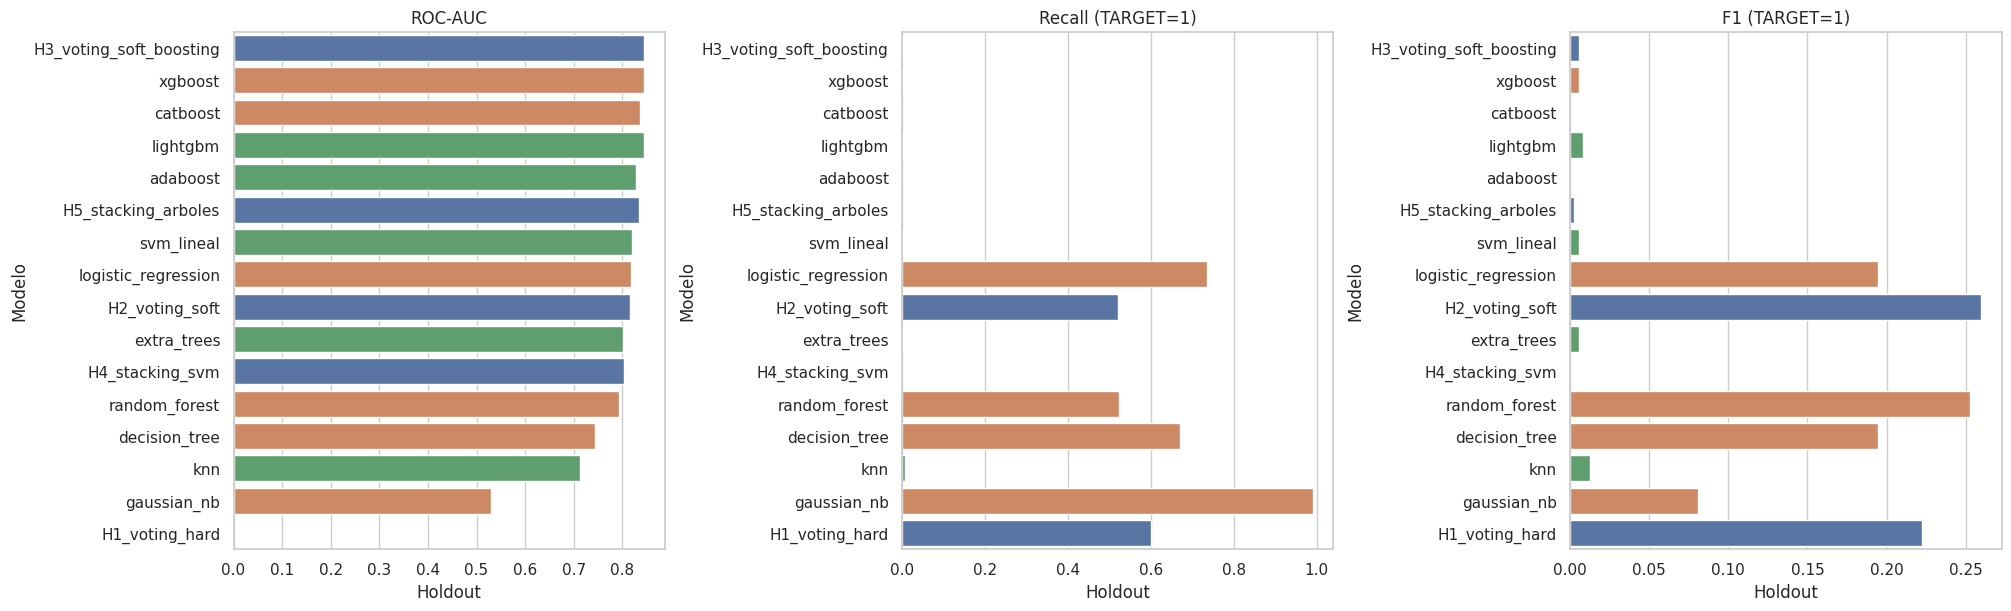

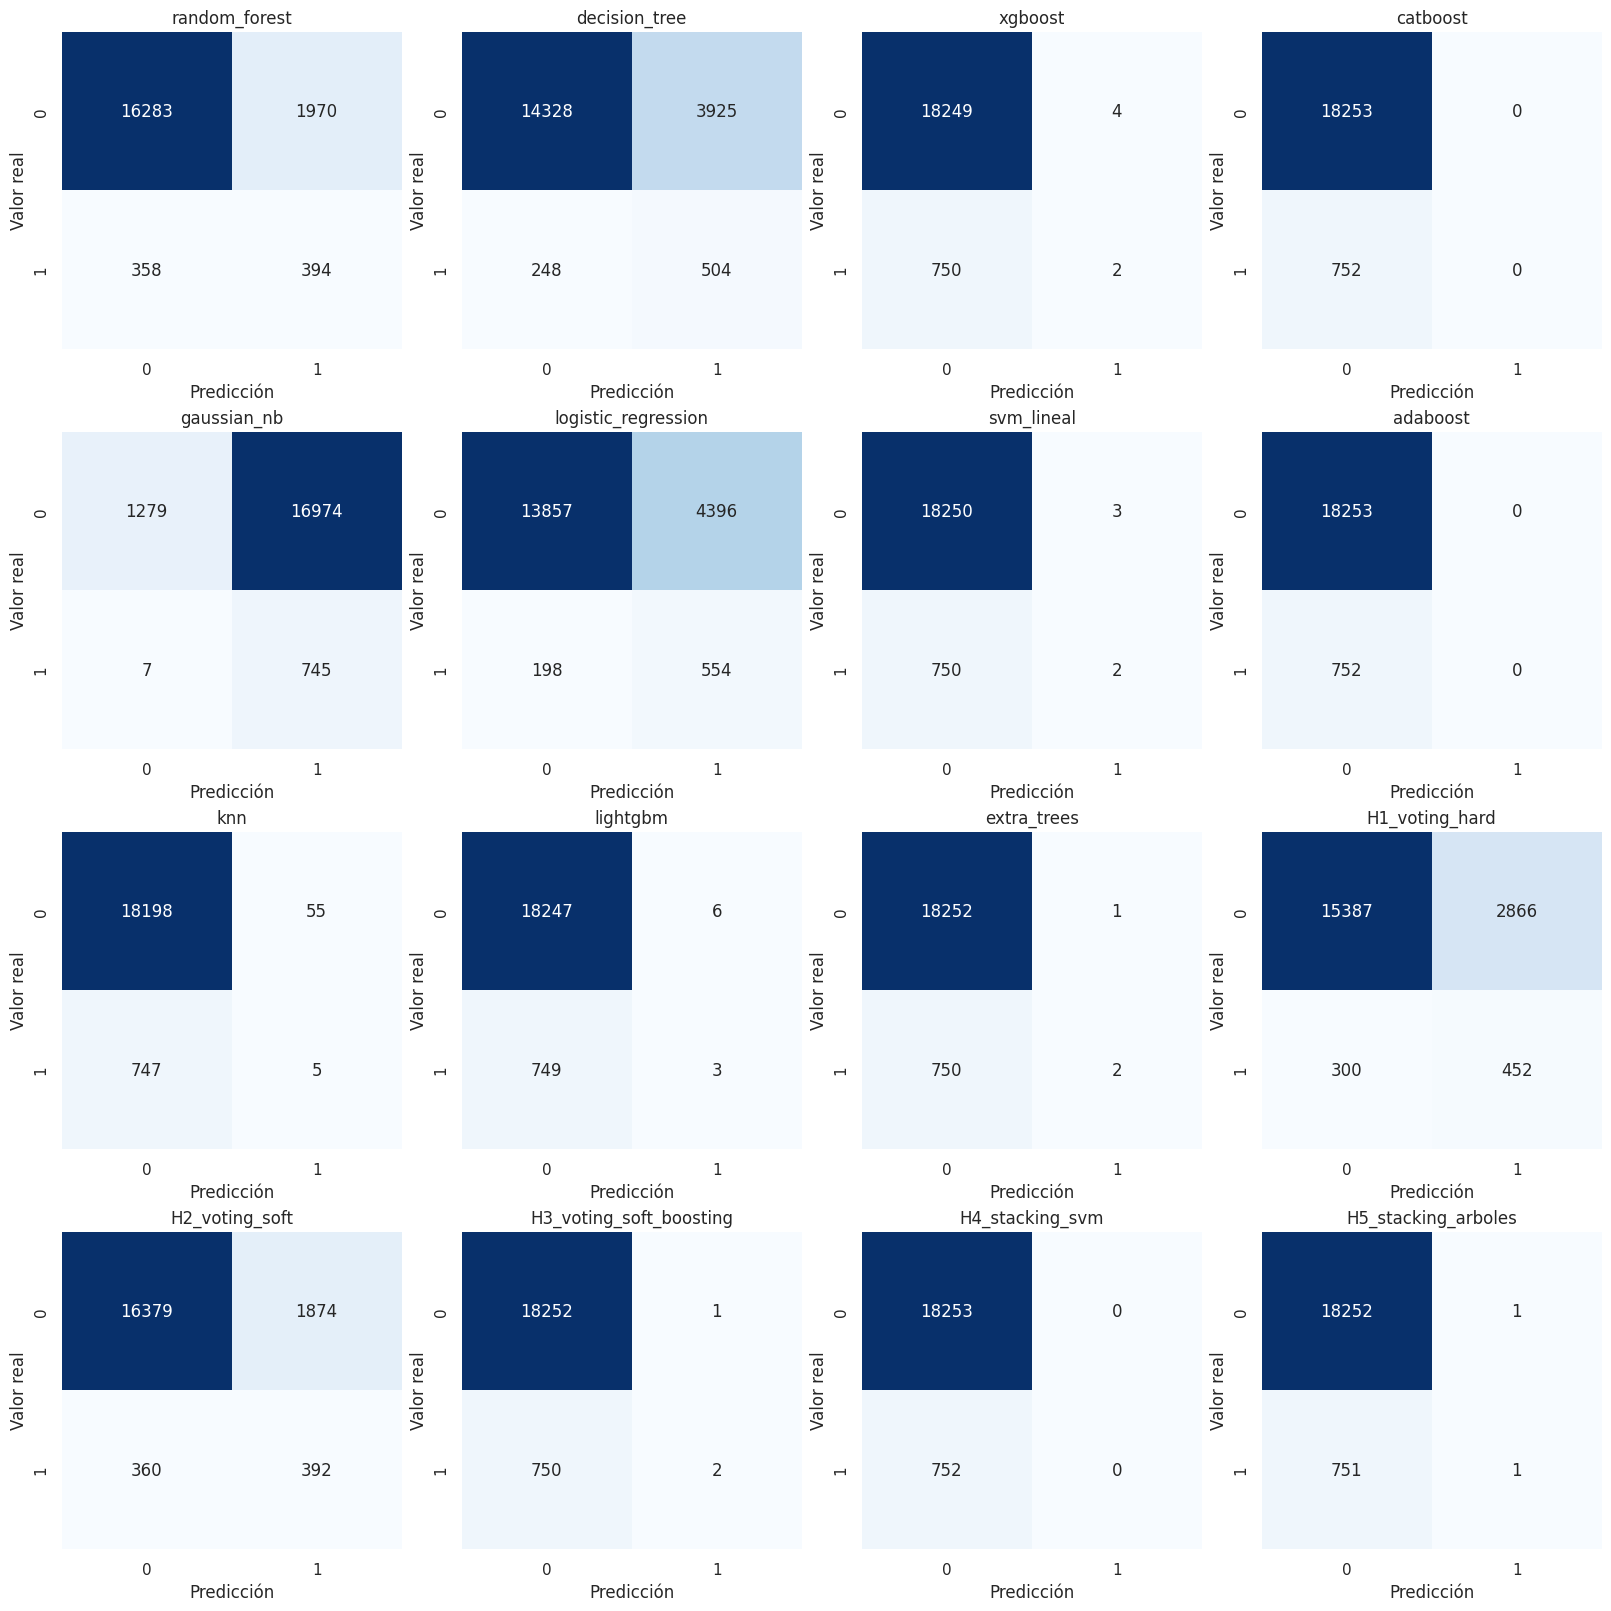

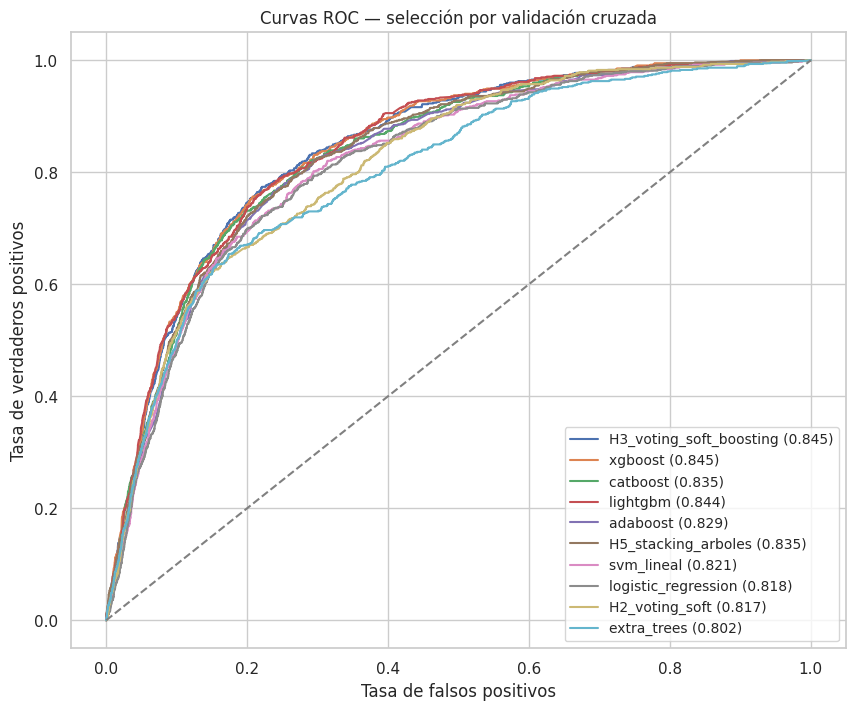

In [22]:
comparacion = tabla_seleccion[['tipo','modelo','escalador','cv_roc_auc','cv_recall',
                                  'cv_f1']].merge(
    tabla_holdout[['tipo','modelo','escalador','accuracy','precision','recall','f1',
                   'roc_auc','average_precision','tiempo_ajuste_s','tiempo_prediccion_s']],
    on=['tipo','modelo','escalador'],validate='one_to_one')
comparacion.to_csv(SALIDA/'comparacion_cv_holdout.csv',index=False)
display(comparacion.sort_values(['cv_roc_auc','cv_recall','cv_f1'],ascending=False,
                                na_position='last').reset_index(drop=True))

fig,axs=plt.subplots(1,3,figsize=(20,6),constrained_layout=True)
orden=comparacion.sort_values('cv_roc_auc',ascending=False,na_position='last')
for ax,metrica,titulo in zip(axs,['roc_auc','recall','f1'],
                            ['ROC-AUC','Recall (TARGET=1)','F1 (TARGET=1)']):
    sns.barplot(data=orden,x=metrica,y='modelo',hue='tipo',dodge=False,ax=ax)
    ax.set(title=titulo,xlabel='Holdout',ylabel='Modelo')
    if ax.legend_ is not None:
        ax.legend_.remove()
plt.savefig(SALIDA/'metricas_holdout.png',dpi=150)
plt.show()

fig,axs=plt.subplots(4,4,figsize=(16,16),constrained_layout=True)
for ax,fila in zip(axs.flat,tabla_holdout.to_dict('records')):
    tipo,nombre=fila['tipo'],fila['modelo']
    p=PREDICCIONES_HOLDOUT[(tipo,nombre)]
    cm=confusion_matrix(p['y_real'],p['y_pred'],labels=[0,1])
    sns.heatmap(cm,annot=True,fmt='d',cbar=False,cmap='Blues',ax=ax,
                xticklabels=[0,1],yticklabels=[0,1])
    ax.set(title=nombre,xlabel='Predicción',ylabel='Valor real')
plt.savefig(SALIDA/'matrices_confusion.png',dpi=140)
plt.show()

fig,ax=plt.subplots(figsize=(10,8))
curvas=0
for _,fila in tabla_seleccion.sort_values('cv_roc_auc',ascending=False,
                                         na_position='last').iterrows():
    if curvas >= 10:
        break
    p=PREDICCIONES_HOLDOUT[(fila['tipo'],fila['modelo'])]
    if p['score'] is None:
        continue
    fpr,tpr,_=roc_curve(p['y_real'],p['score'])
    auc=roc_auc_score(p['y_real'],p['score'])
    ax.plot(fpr,tpr,label=f"{fila['modelo']} ({auc:.3f})")
    curvas+=1
ax.plot([0,1],[0,1],'--',color='gray')
ax.set(title='Curvas ROC — selección por validación cruzada',xlabel='Tasa de falsos positivos',
       ylabel='Tasa de verdaderos positivos')
ax.legend(loc='lower right',fontsize='small')
plt.savefig(SALIDA/'curvas_roc.png',dpi=150)
plt.show()


### Interpretación de las visualizaciones

#### ROC-AUC, Recall y F1

Las figuras muestran perfiles divergentes. H3 alcanza ROC-AUC = 0,845107 y XGBoost = 0,845450, mientras que el Recall de ambos es 0,002660 y su F1 ronda 0,0053. Esto no es una contradicción: ROC-AUC evalúa el ordenamiento de las puntuaciones a lo largo de umbrales posibles; Recall y F1 corresponden a la regla de clasificación actualmente utilizada. Un modelo puede ordenar razonablemente los casos y, sin embargo, dejar casi todos los positivos por debajo del umbral que los convierte en predicciones positivas. H2, en cambio, combina ROC-AUC = 0,816548 con Recall = 0,521277 y F1 = 0,259775 bajo la regla observada.

#### Matrices de confusión

Las matrices, con filas para el valor real y columnas para la predicción, permiten identificar los errores concretos. H3 presenta 2 verdaderos positivos, 750 falsos negativos y 1 falso positivo; H2 registra 392 verdaderos positivos, 360 falsos negativos y 1 874 falsos positivos. La regresión logística obtiene 554 verdaderos positivos y 198 falsos negativos, pero produce 4 396 falsos positivos. H4 no tiene verdaderos positivos y acumula 752 falsos negativos. GaussianNB recupera 745 positivos, aunque genera 16 974 falsos positivos. Estos conteos corresponden a los 752 positivos y 18 253 negativos del holdout.

En la aplicación bancaria descrita, un falso negativo representa a un cliente insatisfecho que el sistema no marcaría para una posible intervención; un falso positivo representa una alerta sobre un cliente satisfecho, que podría desviar atención o recursos. El experimento no midió costos monetarios ni consecuencias de intervención, por lo que no permite cuantificar su impacto ni fijar una preferencia económica entre ambos errores.

#### Curvas ROC

Las configuraciones se seleccionaron utilizando CV sobre desarrollo, mientras que las curvas representadas se calcularon con las puntuaciones de los modelos aplicados al holdout reservado. Una curva más alejada de la diagonal indica mejor capacidad de ordenar positivos por encima de negativos en el conjunto evaluado; la diagonal representa un ordenamiento equivalente al azar. ROC-AUC resume ese comportamiento a través de los umbrales, pero no determina por sí solo la utilidad de un umbral operativo, especialmente con una prevalencia positiva de 3,9569 %. La votación dura H1 no aparece con ROC-AUC porque no genera puntuaciones continuas.

### 4.6.4. Interpretación descriptiva de los resultados

La interpretación prioriza la discriminación de la clase minoritaria `TARGET = 1` y las diferencias entre modelos individuales y ensambles. El ranking se determina mediante CV; el holdout sirve únicamente para comprobar el desempeño final de las configuraciones seleccionadas.

In [23]:
resumen_ordenado = comparacion.sort_values(
    ['cv_roc_auc', 'cv_recall', 'cv_f1'], ascending=False, na_position='last'
)
mejor_configuracion = resumen_ordenado.iloc[0]
print('Clasificación de configuraciones basada exclusivamente en validación cruzada:')
display(resumen_ordenado[['tipo','modelo','escalador','cv_roc_auc','cv_recall','cv_f1',
                         'roc_auc','recall','f1','tiempo_ajuste_s']].reset_index(drop=True))
print('Primera configuración del ranking CV:',
      mejor_configuracion['modelo'], '/', mejor_configuracion['escalador'])
print('ROC-AUC CV:', round(float(mejor_configuracion['cv_roc_auc']), 4)
      if pd.notna(mejor_configuracion['cv_roc_auc']) else 'no definido')
print('La interpretación definitiva se basa en las tablas y figuras observadas;'
      ' las diferencias de puntuaciones no implican significancia estadística.')


Clasificación de configuraciones basada exclusivamente en validación cruzada:


,tipo,modelo,escalador,cv_roc_auc,cv_recall,cv_f1,roc_auc,recall,f1,tiempo_ajuste_s
0,hibrido,H3_voting_soft_boosting,sin_escalado,0.835124,0.001773,0.003537,0.845107,0.002660,0.005298,17.1134
1,original,xgboost,quantile,0.834289,0.003989,0.007909,0.845450,0.002660,0.005277,8.2514
2,original,catboost,robust,0.830896,0.001773,0.003536,0.835289,0.000000,0.000000,6.7995
3,nuevo,lightgbm,standard,0.830218,0.004876,0.009650,0.844143,0.003989,0.007884,6.8124
4,nuevo,adaboost,standard,0.821478,0.000000,0.000000,0.828518,0.000000,0.000000,23.9390
5,hibrido,H5_stacking_arboles,sin_escalado,0.819104,0.002216,0.004419,0.834743,0.001330,0.002653,111.9443
6,nuevo,svm_lineal,quantile,0.813394,0.001773,0.003526,0.820738,0.002660,0.005284,28.5790
7,original,logistic_regression,quantile,0.811790,0.733156,0.199417,0.817760,0.736702,0.194318,122.5971
8,hibrido,H2_voting_soft,sin_escalado,0.803967,0.510195,0.258662,0.816548,0.521277,0.259775,166.5757
9,nuevo,extra_trees,quantile,0.790903,0.000887,0.001768,0.802009,0.002660,0.005298,18.4476


Primera configuración del ranking CV: H3_voting_soft_boosting / sin_escalado
ROC-AUC CV: 0.8351
La interpretación definitiva se basa en las tablas y figuras observadas; las diferencias de puntuaciones no implican significancia estadística.


### Discusión comparativa

El primer lugar según el criterio de selección de CV corresponde a H3 Voting Boosting (ROC-AUC CV = 0,835124). En el holdout, el mayor ROC-AUC observado es el de XGBoost (0,845450), ligeramente superior al de H3 (0,845107); estas cifras describen el conjunto reservado y no sustituyen el ranking de selección. El mayor F1 de holdout corresponde a H2 (0,259775). En Recall, sobresalen regresión logística (0,736702), H1 (0,601064), Random Forest (0,523936) y H2 (0,521277); GaussianNB alcanza 0,990691, pero con Precision = 0,042045 y 16 974 falsos positivos, de modo que ese Recall alto viene acompañado de una carga muy elevada de falsas alertas.

Los híbridos no mejoraron uniformemente a sus componentes. H1 mejora F1 respecto de regresión logística (0,194318) y del árbol (0,194557), pero cede Recall frente a ambos; su ROC-AUC no es calculable. H2 presenta el mayor F1 y una ROC-AUC superior a Random Forest, pero menor Recall que Random Forest y regresión logística y mayor costo de ajuste que sus tres componentes individuales. H3 queda apenas por debajo de XGBoost en ROC-AUC, con prácticamente idéntica y muy baja recuperación; su ajuste es más lento que XGBoost, LightGBM y CatBoost. H4 no mejora a sus integrantes en recuperación y requiere cerca de 789 s. H5 supera a Extra Trees en ROC-AUC (0,834743 frente a 0,802009), pero mantiene Recall casi nulo (0,001330) y su ajuste (111,9443 s) cuesta considerablemente más que Extra Trees (18,4476 s). Frente al árbol, presenta mayor ROC-AUC, pero menor F1 (0,002653 frente a 0,194557); frente a AdaBoost, sus ROC-AUC y F1 son algo mayores (0,834743 frente a 0,828518 y 0,002653 frente a 0), aunque con mayor costo de ajuste. Estas diferencias son descriptivas y no implican significancia estadística.

La Accuracy cercana a 96,04 % observada en varios modelos se explica por el predominio de la clase negativa: predecir casi siempre `TARGET = 0` acierta la mayoría de observaciones sin resolver el objetivo de recuperar insatisfechos. Las diferencias entre las métricas son descriptivas; no se realizaron pruebas de significancia, por lo que no se afirma superioridad estadística. La evidencia separa tres dimensiones: capacidad discriminativa (ROC-AUC y Average Precision), recuperación y balance de clasificación a la regla actual (Recall, Precision, F1 y matrices), y eficiencia (tiempos de ajuste y predicción). La elección depende de la prioridad y de costos que este estudio no cuantificó, por lo que ninguna métrica aislada basta para declarar un ganador general.

### 4.6.5. Trazabilidad y reproducibilidad

La reproducibilidad se documenta mediante la huella del dataset, la semilla, las versiones de bibliotecas, el número de folds y los parámetros de selección de características. Los resultados parciales y finales quedan guardados de forma independiente.

In [24]:
entorno = {
    'dataset_sha256':FIRMA_DATOS,
    'n_registros':int(len(datos)),
    'n_caracteristicas':int(X.shape[1]),
    'n_desarrollo':int(len(X_train)),
    'n_holdout':int(len(X_holdout)),
    'semilla':SEMILLA,
    'folds_externos':FOLDS_EXTERNOS,
    'folds_internos_stacking':FOLDS_STACKING,
    'caracteristicas_seleccionadas_knn':VARIABLES_KNN,
    'configuraciones_cv':int(len(tabla_validacion_ultima)),
    'modelos_holdout':int(len(tabla_holdout)),
    'python':sys.version.split()[0],
    'sklearn':sklearn.__version__,
    'numpy':np.__version__,
    'pandas':pd.__version__,
    'xgboost':package_version('xgboost'),
    'lightgbm':package_version('lightgbm'),
    'catboost':package_version('catboost'),
    'fecha_utc':datetime.now(timezone.utc).isoformat(),
}
guardar_json(SALIDA/'entorno_experimento.json',entorno)
display(pd.DataFrame([entorno]).T.rename(columns={0:'Valor'}))
print('Experimento finalizado. Resultados CSV, JSON y gráficos guardados en:',SALIDA)


,Valor
dataset_sha256,3a3214dbcca233c4f066a2017e33fffc7789cb2c9fc5c0...
n_registros,76020
n_caracteristicas,369
n_desarrollo,57015
n_holdout,19005
semilla,42
folds_externos,2
folds_internos_stacking,3
caracteristicas_seleccionadas_knn,12
configuraciones_cv,49


Experimento finalizado. Resultados CSV, JSON y gráficos guardados en: /content/drive/MyDrive/Santander/Resultados_Final/dd7e6679a71c26b2


### Alcance de reproducibilidad

La semilla 42 y las particiones estratificadas documentan la aleatoriedad controlada de este experimento; el registro identifica Python 3.13.18, scikit-learn 1.6.1, NumPy 2.4.6, pandas 2.2.3, XGBoost 3.4.1, LightGBM 4.6.0 y CatBoost 1.2.10, además de la huella del dataset. Reproducir exactamente las cifras requiere conservar los datos, las versiones y el protocolo indicados. El holdout de 19 005 registros se mantuvo separado del proceso de selección y es la referencia de evaluación final publicada.

KNN utilizó selección supervisada de 12 características dentro de cada fold, lo que reduce la dimensión usada por ese estimador y limita la fuga de información entre particiones. Stacking incorporó validación interna de tres folds para generar predicciones de entrenamiento del metamodelo; esa validación interna no debe confundirse con los dos folds externos utilizados para comparar configuraciones. El número limitado de folds externos restringe la estabilidad con la que se estima el desempeño fuera de muestra.

La tasa positiva de 3,9569 % condiciona fuertemente las métricas y hace visible la dependencia entre Recall, Precision y umbral. Las advertencias guardadas incluyen falta de convergencia de Liblinear, particularmente en H4, y avisos de LightGBM sobre nombres de características durante validación/predicción. Estas advertencias no cambian retrospectivamente los resultados registrados, pero limitan la interpretación de aquellos ajustes afectados.

El experimento no optimizó umbrales ni calibró probabilidades. Los modelos híbridos pueden elevar considerablemente el tiempo de ajuste y predicción, como evidencia H4; las diferencias observadas tampoco se sometieron a pruebas de significancia. Como posibles extensiones, un estudio posterior podría seleccionar umbrales solo mediante validación en desarrollo, evaluar calibración y complementar ROC con análisis Precision–Recall. Esas operaciones no forman parte de los resultados aquí reportados.

## 4.7. Consideraciones metodológicas y limitaciones

Las diferencias de medias observadas en validación cruzada no demuestran por sí mismas significancia estadística. El desbalanceo de clases requiere interpretar Precision, Recall, F1, ROC-AUC y Average Precision conjuntamente. La selección de variables para KNN y los presupuestos reducidos de árboles definen una configuración experimental específica, cuya comparación con alternativas adicionales puede estudiarse por separado.

### Alcance de las conclusiones

El rendimiento final debe interpretarse utilizando los valores efectivamente obtenidos y el tiempo de entrenamiento registrado. La evaluación de holdout permanece separada de la selección de modelos. Los resultados son reproducibles para el conjunto de datos y las versiones de las bibliotecas indicados en el registro de ejecución.

### Conclusiones

En el conjunto de 76 020 observaciones y 369 características, la clase insatisfecha representa 3,9569 %; la división estratificada reservó 19 005 casos como holdout. La validación de 49 configuraciones seleccionó primero a H3 por ROC-AUC CV (0,835124), pero su evaluación final mostró una distinción sustantiva entre ordenamiento y clasificación: ROC-AUC = 0,845107 coexistió con solo 2 verdaderos positivos de 752 y Recall = 0,002660. XGBoost alcanzó el mayor ROC-AUC de holdout (0,845450), con recuperación igualmente baja.

H2 obtuvo el mayor F1 observado (0,259775) y Recall = 0,521277, mientras que H1 y regresión logística privilegiaron una mayor recuperación, con Recall de 0,601064 y 0,736702, respectivamente. Ese perfil implica compromisos distintos en falsos positivos y no establece por sí solo una política de intervención. Varios modelos con ROC-AUC elevado casi no recuperaron positivos bajo la regla actual, mientras que GaussianNB recuperó casi todos a costa de 16 974 falsos positivos.

Los resultados muestran que los ensambles no mejoraron de forma consistente a sus componentes en discriminación, recuperación y F1, y en ciertos casos añadieron un costo considerable: H4 requirió 789,2355 s y no identificó positivos. La evidencia sustenta conclusiones descriptivas para este dataset, esta partición, estas versiones y este protocolo; no demuestra significancia estadística ni define un modelo universalmente superior. Por ello, rendimiento discriminativo, identificación de insatisfechos y costo computacional deben considerarse conjuntamente.